# Assignment 3 — Code Submission (Jupyter Notebook Template)

**Submit:** this `.ipynb` file inside the required ZIP package, together with the required wav_examples/ folder.

**Group members (Name | ID):**  
- `<NAME 1> | <ID 1>`  
- `<NAME 2> | <ID 2>`  
- `<NAME 3> | <ID 3>`  
- `<NAME 4> | <ID 4>`

**Date:** `<DD Month YYYY>`

---

## What the marker should be able to do (end-to-end)
From a fresh environment, the marker should be able to:

1. **Install dependencies** (from your provided dependencies file)  
2. **Run training** for each experiment (or run your provided trained checkpoints, if allowed by the task sheet)  
3. **Run inference**: input plain text → output a playable `.wav` file  
4. **See evidence**: objective metric(s) + qualitative samples (≥10 text prompts with corresponding `.wav` outputs)

---

## Expected artefacts / recommended structure
You can adapt this, but keep it **clear and reproducible**.

- `dependencies.*` (choose one): `requirements.txt` / `environment.yml` / `pyproject.toml`  
- `scripts/`
  - `train.py` (or `train_expA.py`, `train_expB.py`, etc.)
  - `synth.py` (single “text → wav” entrypoint recommended)
  - `evaluate.py` (objective metric computation)
- `configs/` (optional but recommended)
  - `expA.yaml`, `expB.yaml`, ...
- `results/`
  - `wavs/` (generated audio samples; **≥10 prompts**)
  - `metrics.json` or `metrics.csv`
  - `spectrograms/` (optional)

> Note: Spectrograms are **optional** unless your task sheet explicitly requires them. If you include them, provide 2–3 representative examples per experiment.

---

## How to use this notebook
- Use the headings below as your “evidence checklist”.
- Add **code cells** directly under each heading for implementation and outputs (tables, logs, plots, audio).
- Keep paths consistent and relative where possible.

In [1]:
import os
import re
import json
import random
import unicodedata
from pathlib import Path
from typing import Dict, List, Optional, Tuple
import yaml

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torchaudio 
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from IPython.display import Audio, display

DATASET = Path("dataset/LJSpeech-1.1/")
METADATA_PATH = DATASET / "metadata.csv"
DATA_PATH = DATASET / "wavs"

# 1.1 Dataset handling & pre-processing (Rubric 1.1)

## 1.1.1 Dataset location and structure
- **Dataset:** LJSpeech  
- **Local path used:** `dataset/LJSpeech-1.1`  
- **Files/folders used:**  
  - `metadata.csv`  
  - `wavs/`

## 1.1.2 Audio preprocessing (document your choices)
State what you did and why:
- **Sampling rate:** `original`
  - Sample rate is how many times per seconds the microphone measures the air pressure, a sample rate of $s$ can only capture audio frequencies up to $\frac{s}{2}$. Natively the frequency is 22,050 Hz so it can capture up to 11,025 Hz which we have kept the same as this mimics the natural audible requency range for human speech.
- **Silence trimming / padding:** `-40 dB root mean squared energy threshold (20 ms window, 5 ms hop) and a 50 ms trailing zero pad`
  - The -40 dB root mean squared energy threshold is to cut out any noise
  - The trailing 50ms of 0 dB to give me the model a clear sense of the end of a sample.
- **Any filtering / normalization:** `DC Offset Removal & Peak Normalization`
  - DC Offset, waveform - waveform.mean(), cheap or slightly uncalibrated recording equipment can shift a soundwave slightly above or below zero so "silence" sits at 0.02 instead of 0.0, mean centering forces the wave back at zero so silent regions have zero energy.
  - Peak Normalization, waveform / max(abs(waveform)) * 0.95, every audio clip is scaled its loudest peak reaches 0.95. Without this, the neural network can confuse emphasis and volumes on certain words so we shrink the magnitude of volume by 95% to allow for headroom so convolutional filters don't clip (saturate) the wave at the boundaries.

## 1.1.3 Text preprocessing (minimum: justify your choice)
- **Normalisation:** `NFKC Unicode & Lowercasing & Number/Abbreviation Expansion`
  - LJSpeech transcripts come from 19th-century books and contain curly quotes, em-dashes, and accented characters, which are not part of a standardised unicode language, NFKC normalization converts the unknown symbols into standard equivalents, and mapping to symbols such as ';', ':', and '—', this way the network is not introduced to uncommon strange characters and there is a fixed, reduced, known set of characters for training.
  - In an LLM, capital letters help distinguish proper nouns and beginning of sentences which helps with emphasis and phrasing. However for a single voice TTS model keeping uppercase letters doubles the alphabet for the exact same sounds. In addition, capital letters appear much less frequently than lowercase letters, the model learns poor embeddings for uppercase tokens.
  - LJSpeech's metadata.csv has three columns: ID, Raw Text and Normalized Text. For example, column 2 have numbers like 1 and 12 and it might also have abbreviations like Mr. and Ms. and symbols such as +. Column 3 has the expanded text such as one and 12, Mister and Miss and plus. We explicitly pull from column 3 and have regex for that maps abbreviations to their full because characters as "1" or "+" have zero phonetic correlation with the sounds.
- **Tokeniser / phonemiser (if used):** `Tokeniser & Phonemiser Used>`
  - The phonemiser converts english into phonetic sequences prior to tokenisation. Without it we would have to force the encoder to memorise complex spelling exceptions and english pronouciations. Converting text to phonemes provides a near 1 to 1 mapping between input symbols and physical sounds, results in faster alignment convergence and higher pronunciation accuracy.
  - The tokeniser maps the character or phoneme symbols to integer IDs and can add a blank token, `0`, between every input token which is required by non autoregressive architectures like VITS to model transitions and brief silences between sounds.

## 1.1.4 Train/validation/test split (reproducible)
- **Split ratio:** `90/5/5`
  - Due to the high data consumption needed to train a generative model and the large amount of data 90/5/5 is fine as 5% is still 630 utterances for validation and testing. 
- **Seed:** `42`  
- **How split is created:** `Lexiographical Sort & Shuffle by Seed & Duration Filtering`
  - Sort the dataframe into strict alphabetical order by filename ID as harddrives on different OS can read file order differently.
  - Shuffle on seed to mix the dataset with the same seed and order every group member should have the same order.
  - Filter out clips less than 1.0 seconds as they might not have any value and filter out clips greater than 10.0 seconds as they can skew the split of the dataset.
  - The dataset is then split down its split ratios 90/5/5.
- **Any subset used:** `Duration filtered subset only 12,600 of 13,100 utterances retained`

In [2]:
# (Optional) Put small sanity-check code here:
# - verify LJSpeech files exist
# - read metadata.csv
# - build split lists
# - print counts
from scripts.TextProcessor import TextProcessor
from scripts.DataLoader import DataConfig, build_splits, LJSpeechDataset, TTSCollate, build_dataloaders

cfg = DataConfig(
    data_root="./dataset/LJSpeech-1.1",
    output_split_dir="./dataset/splits",
)

train_df, val_df, test_df, summary = build_splits(cfg)

In [3]:
print("=== SPLIT SIZES ===")
print(f"Splits = Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

with open(Path(cfg.output_split_dir) / "split_summary.json", 'r') as file: data = json.load(file) 
    
split_hours = data.get("split_hours", {})
    
train_hours = split_hours.get("train")
val_hours = split_hours.get("val")
test_hours = split_hours.get("test")
print(f"Splits Hours = Train: {train_hours} | Val: {val_hours} | Test: {test_hours}")
total_hours = train_hours + val_hours + test_hours
print(f"Splits Ratio by Time = Train: {round(train_hours/total_hours, 4)} | Val: {round(val_hours/total_hours, 4)} | Test: {round(test_hours/total_hours, 4)}")

=== SPLIT SIZES ===
Splits = Train: 2700 | Val: 150 | Test: 150
Splits Hours = Train: 4.941 | Val: 0.275 | Test: 0.272
Splits Ratio by Time = Train: 0.9003 | Val: 0.0501 | Test: 0.0496


In [4]:
print("=== TEXT VERIFICATION ===")

text_processor = TextProcessor(add_blank=cfg.add_blank)
train_set = LJSpeechDataset(train_df, cfg=cfg, text_processor=text_processor)
val_set = LJSpeechDataset(val_df, cfg=cfg, text_processor=text_processor)
test_set = LJSpeechDataset(test_df, cfg=cfg, text_processor=text_processor)

# Fetch sample 0 of each 
samples = [("train", train_set[0]), ("val", val_set[0]), ("test", test_set[0])]
for sample in samples:
    
    split = sample[0]
    dataframe = sample[1]

    print(f"{split} set")
    print(f"- Utterance ID : {dataframe['utt_id']}")
    print(f"- Raw Text : {dataframe['raw_text']}")
    print(f"- Normalised Text : {dataframe['norm_text']}")
    print(f"- Cleaned Text : {dataframe['clean_text']}")
    
    decoded_ipa = text_processor.sequence_to_text(dataframe["token_ids"])
    tokens = dataframe["token_ids"].tolist()
    non_blank_count = sum(1 for t in tokens if t != text_processor.blank_id)
    
    print(f"- Decoded IPA : {decoded_ipa}")
    print(f"- First 10 Token IDs : {tokens[:10]}")
    print(f"- Total {split} Tokens : {len(tokens)} | Expected (2 * {non_blank_count} + 1): {2 * non_blank_count + 1}")
    assert len(tokens) == 2 * non_blank_count + 1, print(f"Intersperesed tokens mismatch {tokens}")
    assert all(t == 0 for t in tokens[0::2]), "Even indices must all be blank_id (0)!"



=== TEXT VERIFICATION ===
train set
- Utterance ID : LJ033-0138
- Raw Text : It was the appropriate size to contain, in disassembled form,
- Normalised Text : It was the appropriate size to contain, in disassembled form,
- Cleaned Text : it was the appropriate size to contain, in disassembled form,
- Decoded IPA : ɪt wʌzðɪ ɐpɹˈoʊpɹɪət sˈaɪz tə kəntˈeɪn, ɪn dˌɪsɐsˈɛmbəld fˈɔːɹm,
- First 10 Token IDs : [0, 103, 0, 63, 0, 17, 0, 66, 0, 139]
- Total train Tokens : 129 | Expected (2 * 64 + 1): 129
val set
- Utterance ID : LJ043-0109
- Raw Text : In New Orleans he obtained work as a greaser and oiler of coffee processing machines for the William B. Reily Co.,
- Normalised Text : In New Orleans he obtained work as a greaser and oiler of coffee processing machines for the William B. Reily Co.,
- Cleaned Text : in new orleans he obtained work as a greaser and oiler of coffee processing machines for the william b. reily co.,
- Decoded IPA : ɪn nˈuː ˈɔːɹliənz hiː əbtˈeɪnd wˈɜːk æz ɐ ɡɹˈiːsɚ ænd ˈ

In [5]:
print("=== AUDIO VERIFICATION ===")
for sample in samples:
    split = sample[0]
    dataframe = sample[1]

    print(f"{split} set")
    wav_len = dataframe["waveform"].size(-1)
    spec_frames = dataframe["linear_spec"].size(-1)
    mel_frames = dataframe["log_mel"].size(-1)
    expected_frames = wav_len // cfg.hop_length
    
    print(f"- Waveform shape : {tuple(dataframe['waveform'].shape)} ({dataframe['duration_sec']:.2f}s * {dataframe['sample_rate']}Hz)")
    print(f"- Linear Spec shape : {tuple(dataframe['linear_spec'].shape)} (Expected bins={cfg.n_fft // 2 + 1})")
    print(f"- Log Mel shape : {tuple(dataframe['log_mel'].shape)} (Expected bands={cfg.n_mels})")
    print(f"- Frame alignment : Spec Frames = {spec_frames} | Wav // 256 + 1 = {expected_frames}")
    assert spec_frames == mel_frames == expected_frames, "STFT frame count and waveform hop ratio mismatch"
    
    display(Audio(dataframe["waveform"].numpy(), rate=cfg.target_sr))

=== AUDIO VERIFICATION ===
train set
- Waveform shape : (1, 96143) (4.36s * 22050Hz)
- Linear Spec shape : (513, 375) (Expected bins=513)
- Log Mel shape : (80, 375) (Expected bands=80)
- Frame alignment : Spec Frames = 375 | Wav // 256 + 1 = 375


val set
- Waveform shape : (1, 190743) (8.65s * 22050Hz)
- Linear Spec shape : (513, 745) (Expected bins=513)
- Log Mel shape : (80, 745) (Expected bands=80)
- Frame alignment : Spec Frames = 745 | Wav // 256 + 1 = 745


test set
- Waveform shape : (1, 188433) (8.55s * 22050Hz)
- Linear Spec shape : (513, 736) (Expected bins=513)
- Log Mel shape : (80, 736) (Expected bands=80)
- Frame alignment : Spec Frames = 736 | Wav // 256 + 1 = 736


In [11]:
print("=== DATALOADER VERIFICATION ===")

collate_fn = TTSCollate()

loaders = build_dataloaders(cfg=cfg, batch_size=16, num_workers=0)

train_loader = loaders["train"]
val_loader = loaders["val"]
test_loader = loaders["test"]

batches = [("train", next(iter(train_loader))), ("val",   next(iter(val_loader))), ("test",  next(iter(test_loader)))]

for sets in batches:
    split = sets[0]
    batch = sets[1]
    
    print(f"{split} set")
    print(f"- First 5 Batch Utterance IDs : {batch['utt_ids'][:5]}")
    print(f"- text_padded shape : {tuple(batch['text_padded'].shape)} | dtype: {batch['text_padded'].dtype}")
    print(f"- text_lengths : {batch['text_lengths'].tolist()}")
    print(f"- spec_padded shape : {tuple(batch['spec_padded'].shape)} | dtype: {batch['spec_padded'].dtype}")
    print(f"- mel_padded shape : {tuple(batch['mel_padded'].shape)} | dtype: {batch['mel_padded'].dtype}")
    print(f"- spec_lengths : {batch['spec_lengths'].tolist()}")
    print(f"- wav_padded shape : {tuple(batch['wav_padded'].shape)} | dtype: {batch['wav_padded'].dtype}")
    print(f"- wav_lengths : {batch['wav_lengths'].tolist()}")
    
    spec_lens = batch["spec_lengths"].tolist()
    assert spec_lens == sorted(spec_lens, reverse=True), "Batch is not sorted descending by spec_lengths"
    
    shortest_idx = -1
    text_len = batch["text_lengths"][shortest_idx].item()
    spec_len = batch["spec_lengths"][shortest_idx].item()
    wav_len  = batch["wav_lengths"][shortest_idx].item()

    text_padding  = batch["text_padded"][shortest_idx, text_len:]
    spec_padding = batch["spec_padded"][shortest_idx, :, spec_len:]
    wav_padding   = batch["wav_padded"][shortest_idx, :, wav_len:]
    
    assert torch.all(text_padding == 0),   "Non-zero found in token collate padding"  
    assert torch.all(spec_padding == 0.0), "Non-zero found in spectrogram collate padding"
    assert torch.all(wav_padding == 0.0),  "Non-zero found in waveform collate padding"
    print("- Collate padding is accurate and all zero")

=== DATALOADER VERIFICATION ===
train set
- First 5 Batch Utterance IDs : ['LJ008-0020', 'LJ023-0015', 'LJ040-0122', 'LJ043-0057', 'LJ030-0124']
- text_padded shape : (16, 295) | dtype: torch.int64
- text_lengths : [259, 259, 289, 295, 273, 197, 225, 233, 207, 209, 155, 191, 173, 169, 143, 119]
- spec_padded shape : (16, 513, 837) | dtype: torch.float32
- mel_padded shape : (16, 80, 837) | dtype: torch.float32
- spec_lengths : [837, 789, 761, 742, 731, 631, 629, 625, 593, 588, 522, 510, 419, 372, 358, 334]
- wav_padded shape : (16, 1, 214283) | dtype: torch.float32
- wav_lengths : [214283, 202073, 195033, 190083, 187223, 161703, 161153, 160053, 152023, 150593, 133763, 130683, 107473, 95373, 91743, 85583]
- Collate padding is zero
val set
- First 5 Batch Utterance IDs : ['LJ050-0140', 'LJ001-0109', 'LJ015-0193', 'LJ042-0088', 'LJ043-0109']
- text_padded shape : (16, 291) | dtype: torch.int64
- text_lengths : [291, 271, 257, 257, 245, 271, 251, 277, 253, 237, 231, 207, 185, 199, 131, 83]

=== WAVEFORM & SPECTROGRAM VERIFICATION ===
train set


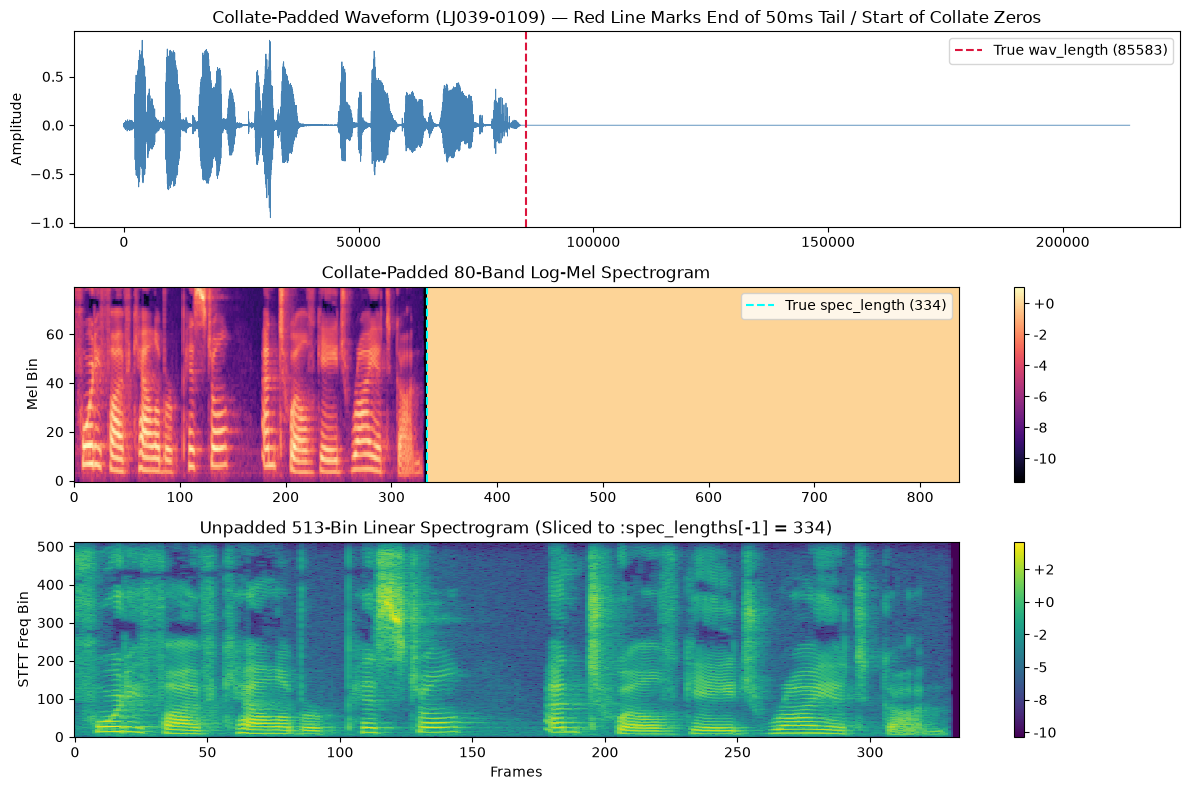

val set


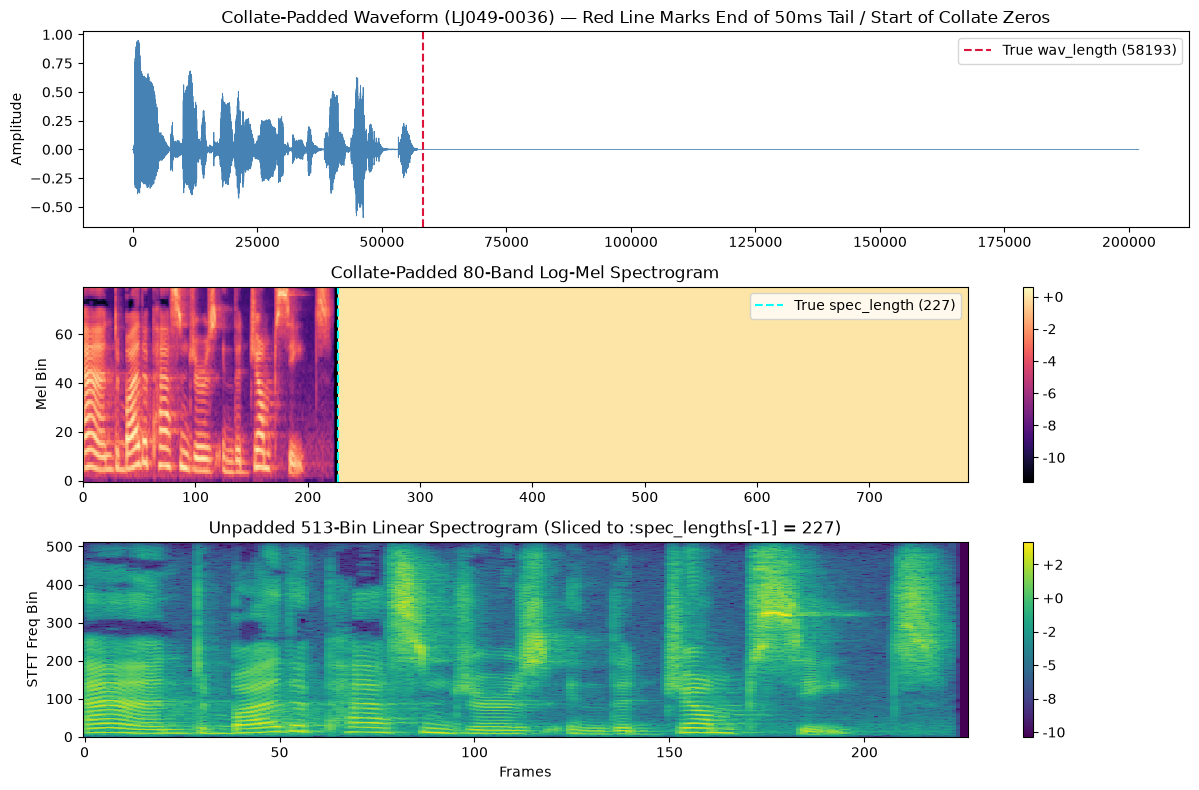

test set


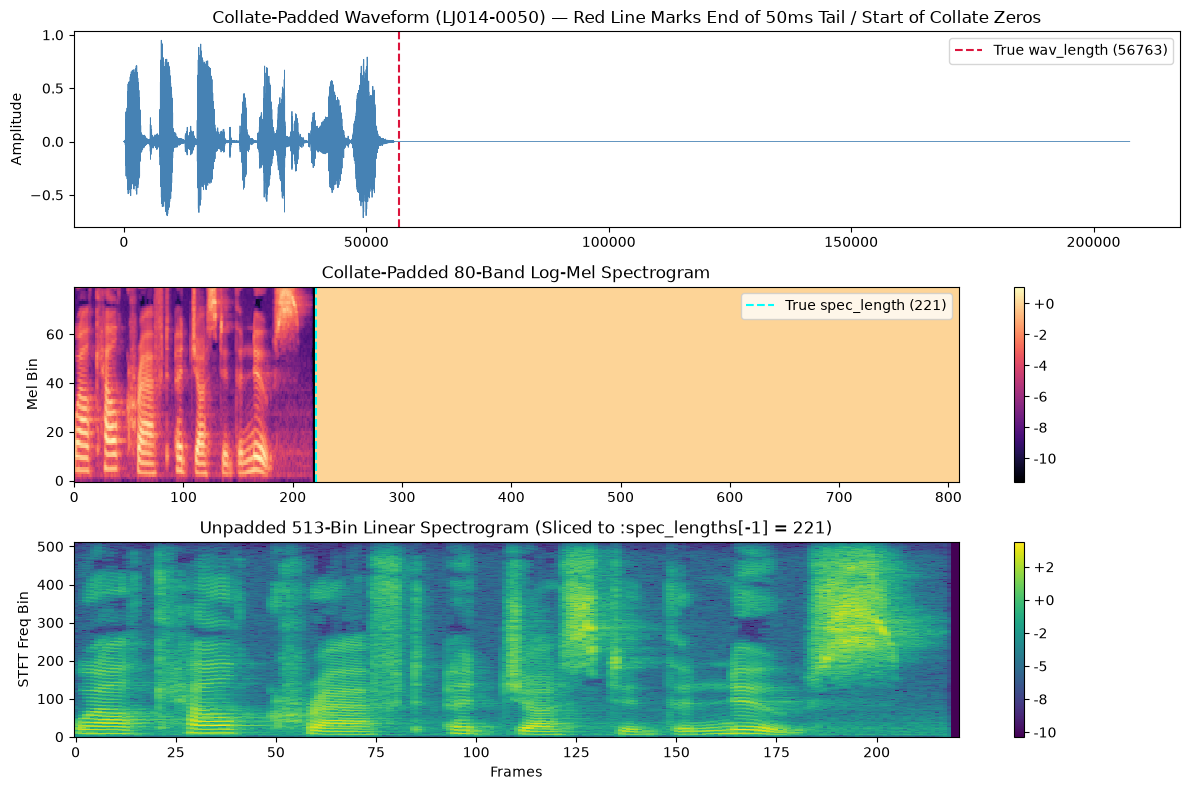

In [14]:
print("=== WAVEFORM & SPECTROGRAM VERIFICATION ===")

for sets in batches:
    split = sets[0]
    batch = sets[1]
    
    print(f"{split} set")
    fig, axes = plt.subplots(3, 1, figsize=(12, 8))
    
    # Plot the shortest sample in the batch to see the real data + zero-padding tail
    idx = -1
    utt_id = batch["utt_ids"][idx]
    s_len = batch["spec_lengths"][idx].item()
    w_len = batch["wav_lengths"][idx].item()
    
    # Padded Waveform
    waveform = batch["wav_padded"][idx, 0].numpy()
    axes[0].plot(waveform, color="steelblue", linewidth=0.6)
    axes[0].axvline(w_len, color="crimson", linestyle="--", linewidth=1.5, label=f"True wav_length ({w_len})")
    axes[0].set_title(f"Collate-Padded Waveform ({utt_id}) — Red Line Marks End of 50ms Tail / Start of Collate Zeros")
    axes[0].set_ylabel("Amplitude")
    axes[0].legend(loc="upper right")
    
    # Padded Log-Mel Spectrogram
    mel_spec = batch["mel_padded"][idx].numpy()
    im1 = axes[1].imshow(mel_spec, aspect="auto", origin="lower", interpolation="none", cmap="magma")
    axes[1].axvline(s_len, color="cyan", linestyle="--", linewidth=1.5, label=f"True spec_length ({s_len})")
    axes[1].set_title("Collate-Padded 80-Band Log-Mel Spectrogram")
    axes[1].set_ylabel("Mel Bin")
    axes[1].legend(loc="upper right")
    fig.colorbar(im1, ax=axes[1], format="%+2.0f")
    
    # Unpadded Linear Spectrogram (what the model ius actually seeing)
    lin_spec = torch.log(torch.clamp(batch["spec_padded"][idx, :, :s_len], min=1e-5)).numpy()
    im2 = axes[2].imshow(lin_spec, aspect="auto", origin="lower", interpolation="none", cmap="viridis")
    axes[2].set_title(f"Unpadded 513-Bin Linear Spectrogram (Sliced to :spec_lengths[{idx}] = {s_len})")
    axes[2].set_ylabel("STFT Freq Bin")
    axes[2].set_xlabel("Frames")
    fig.colorbar(im2, ax=axes[2], format="%+2.0f")
    
    plt.tight_layout()
    plt.show()

# 1.2 End-to-end TTS pipeline implementation (Rubric 1.2)

## 1.2.1 Pipeline overview (high level)
Describe the approach briefly:
- **TTS approach:** `<fine-tune a toolkit/model; or custom pipeline>`  
- **Key components:**  
  - Text front-end: `<normalisation/tokenisation/phonemes>`  
  - Acoustic model: `<name / architecture / settings>`  
  - Vocoder / waveform generator: `<name / settings>`  
- **Output:** playable `.wav` waveform

## 1.2.2 Environment & dependencies (reproducible)
Provide at least one dependency definition file and document:
- **OS:** `<e.g., Ubuntu 22.04 / Windows 11 / macOS>`  
- **Python:** `<version>`  
- **CUDA (if used):** `<version>`  
- **GPU (if used):** `<model + VRAM>`

✅ Include: `requirements.txt` or `environment.yml` (or equivalent)

## 1.2.3 Training command(s)
Provide the exact command(s) you used, for example:
- `python scripts/train.py --config configs/expA.yaml`
- `python scripts/train.py --config configs/expB.yaml`

If you use a framework launcher, include that too (e.g., `accelerate launch ...`).

## 1.2.4 Inference: a single “text → wav” entrypoint (must be easy to run)
Provide a minimal command that generates a waveform file from text, for example:
- `python scripts/synth.py --text "Hello world." --checkpoint checkpoints/expA.ckpt --out wav_examples/hello.wav`

Also state:
- Where checkpoints are stored / how to download them (if applicable)
- Where generated wavs are saved by default

In [7]:

# (Optional) Put your pipeline wiring here:
# - load model + vocoder
# - synthesize from a single input text
# - write .wav to wav_examples/

# 1.3 Experimental methodology (Rubric 1.3)

## 1.3.1 Controlled experiments (minimum: 2)
Define at least two experiments that share the **same split** and differ by a clearly stated change.

### Experiment A (baseline)
- **Name:** `expA`  
- **Purpose:** `<baseline objective>`  
- **Key settings:** `<model, vocoder, steps/epochs, batch size, lr, etc.>`

### Experiment B (controlled change)
- **Name:** `expB`  
- **Controlled change vs expA:** `<one major variable is best>`  
- **Key settings:** `<only what differs + key training settings>`

## 1.3.2 What you saved for reproducibility
- Config files: `<paths>`
- Random seeds: `<where set>`
- Checkpoints: `<paths>`
- Logs: `<paths>`

In [8]:

# (Optional) Run/record your experiment commands here (or print them):
# !python scripts/train.py --config configs/expA.yaml
# !python scripts/train.py --config configs/expB.yaml

# (Required) Produce qualitative samples (≥10 prompts) and save wavs
# Example pattern:
# prompts = [...]
# for i, t in enumerate(prompts):
#     out = f"wav_examples/sample_{i:02d}.wav"
#     synthesize_to_wav(text=t, checkpoint="...", out_path=out)

# (Required) Compute objective metric(s) and report metric results clearly in the notebook.# 1.4 Evaluation, coding practice & attribution (Rubric 1.4)

## 1.4.1 Objective metric (minimum: 1) — report for each experiment
Implement and report at least one objective metric for **each** experiment, e.g.:
- **Latency:** average synthesis time per sentence (state number of runs)  
- **Real-Time Factor (RTF):** synthesis_time / audio_duration  
- **Other justified metric:** `<describe and justify>`

Report results in a small table (in this notebook)

## 1.4.2 Qualitative evaluation (required)
Provide **≥10 text prompts** and corresponding **generated `.wav` outputs** (per your task requirements).  
Include:
- The list of prompts you used
- Where the `.wav` files are saved (`wav_examples/…`)
- (Optional) a short comment on perceptual quality differences between experiments

> Spectrograms are optional unless explicitly required by your task sheet. If you include them, add 2–3 representative samples per experiment in `results/spectrograms/`.

## 1.4.3 Coding practice & clarity
Briefly state:
- How you organised code (modules/scripts/configs)
- Any key engineering choices that improve reproducibility (fixed seeds, clear CLI args, etc.)

## 1.4.4 Attribution / external resources
List any:
- External libraries/models/toolkits used
- Pretrained checkpoints used
- Tutorials or code snippets adapted (with links in your report; in this notebook, name them clearly)

## 1.4.5 AI use statement (if any)
State whether you used generative AI tools, and for what (e.g., debugging, refactoring, documentation).  
If used, specify what you verified yourself and what parts were AI-assisted.

# (Required) Produce qualitative samples (≥10 prompts) and save wavs
# Example pattern:
# prompts = [...]
# for i, t in enumerate(prompts):
#     out = f"wav_examples/sample_{i:02d}.wav"
#     synthesize_to_wav(text=t, checkpoint="...", out_path=out)
# (Required) Compute objective metric(s) and report metric results clearly in the notebook.

# Final verification (before submission)

## Restart & run
Restart the kernel and run all cells you want the marker to execute, ensuring:
- No hidden dependencies on your local machine paths
- Commands/paths work from the submission root

## Confirm required artefacts exist
- `wav_examples/` contains generated `.wav` outputs (**≥10 prompts**)  
- bjective metric results for each experiment are clearly reported in the notebook
- dependency file exists (`requirements.txt` / `environment.yml` / etc.)  
- inference entrypoint works (single command that takes text and outputs wav)

## Marker instructions (one paragraph)
Write a short paragraph here telling the marker **exactly** how to:
1) install deps, 2) run training (or load checkpoints), 3) run inference demo, 4) locate results.